# K-Means — watch the centroids move

**Introductory lab · 30–40 minutes**

Eight deliberately chosen map locations make every calculation traceable. They are hand-built teaching data, with both coordinates in the same units. We seek groups of nearby locations. Use this before the Mall Customers activity.

Run cells in order in Jupyter or Colab. All data are embedded. If dependencies are missing, uncomment the installation command. Predict each result before running the next step.

In [1]:
# %pip install numpy pandas matplotlib scipy scikit-learn

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.metrics import adjusted_rand_score, silhouette_score
plt.rcParams.update({'figure.figsize': (7, 5), 'font.size': 11})


,Horizontal,Vertical
A,1.0,1.0
B,1.5,2.0
C,3.0,1.5
D,5.0,4.0
E,6.0,5.0
F,7.0,4.5
G,8.0,8.0
H,9.0,8.5


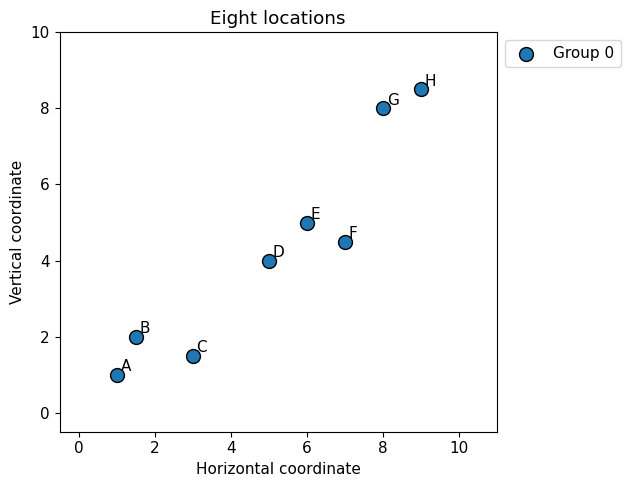

In [3]:
X = np.array([[1,1],[1.5,2],[3,1.5],[5,4],[6,5],[7,4.5],[8,8],[9,8.5]], dtype=float)
names = np.array(list('ABCDEFGH'))
display(pd.DataFrame(X,index=names,columns=['Horizontal','Vertical']))
def plot_groups(points, groups, title, centers=None):
    fig, ax = plt.subplots()
    for group in np.unique(groups):
        selected = groups == group
        color = 'lightgray' if group < 0 else plt.cm.tab10(int(group) % 10)
        ax.scatter(points[selected,0], points[selected,1], s=100, color=color,
                   edgecolor='black', label=f'Group {group}' if group >= 0 else 'Unassigned / noise')
    for i, point in enumerate(points):
        ax.annotate(names[i], point + .10)
    if centers is not None:
        ax.scatter(centers[:,0], centers[:,1], marker='X', s=260, c='red', label='Centroids')
    ax.set(xlabel='Horizontal coordinate', ylabel='Vertical coordinate', title=title)
    ax.set_xlim(-.5, 11); ax.set_ylim(-.5, 10); ax.set_aspect('equal')
    ax.legend(loc='upper left', bbox_to_anchor=(1,1)); plt.tight_layout(); plt.show()
plot_groups(X, np.zeros(len(X),dtype=int), 'Eight locations')

## 1. Choose three initial centers
K-Means alternates assignment and update steps to reduce
$$J=\sum_i\|x_i-\mu_{c_i}\|^2.$$
The assignment uses the nearest center. The updated center is the arithmetic mean of its assigned points.
$$\mu_k=\frac{1}{|C_k|}\sum_{i\in C_k}x_i.$$
We deliberately start all three centers near the lower-left corner so their movement is visible. These fixed starting positions let us compare exactly with scikit-learn.

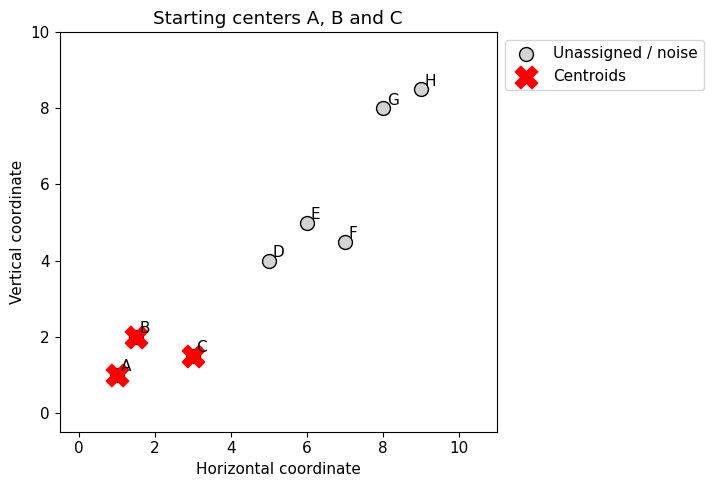

In [4]:
initial = X[[0,1,2]].copy()
centers = initial.copy()
plot_groups(X, np.full(len(X),-1), 'Starting centers A, B and C', centers)

## 2. Inspect the first distance table
Distances are squared Euclidean distances. Squaring preserves which center is nearest. Predict the group of H. Ties are assigned to the first minimum.

In [5]:
distances = ((X[:,None,:]-centers[None,:,:])**2).sum(axis=2)
assignments = distances.argmin(axis=1)
table = pd.DataFrame(distances,index=names,columns=['Center 0','Center 1','Center 2'])
table['Chosen group'] = assignments
display(table.round(3))


,Center 0,Center 1,Center 2,Chosen group
A,0.00,1.25,4.25,0
B,1.25,0.00,2.50,1
C,4.25,2.50,0.00,2
D,25.00,16.25,10.25,2
E,41.00,29.25,21.25,2
F,48.25,36.50,25.00,2
G,98.00,78.25,67.25,2
H,120.25,98.50,85.00,2


## 3. Follow every iteration
Each pair of plots shows assignment to the current centers, then movement to the new means. Read the member table between plots. The loop stops when centers stop moving. An empty group keeps its previous center in this teaching implementation.

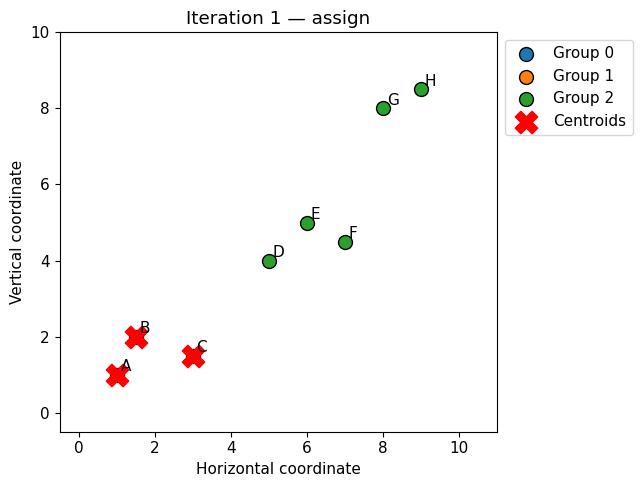

,Members,New x,New y
0,A,1.000000,1.00
1,B,1.500000,2.00
2,C D E F G H,6.333333,5.25


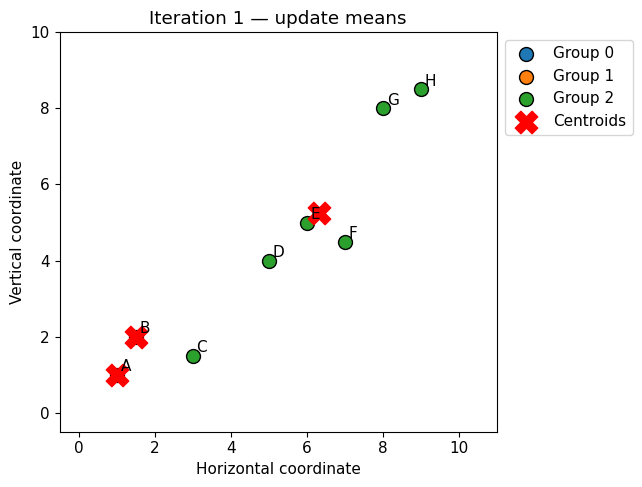

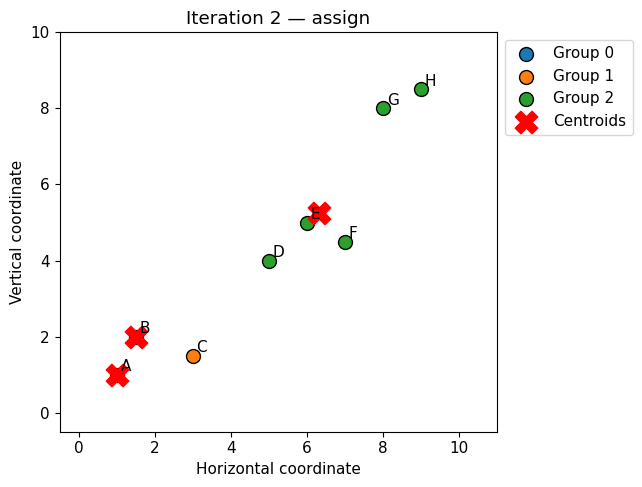

,Members,New x,New y
0,A,1.00,1.00
1,B C,2.25,1.75
2,D E F G H,7.00,6.00


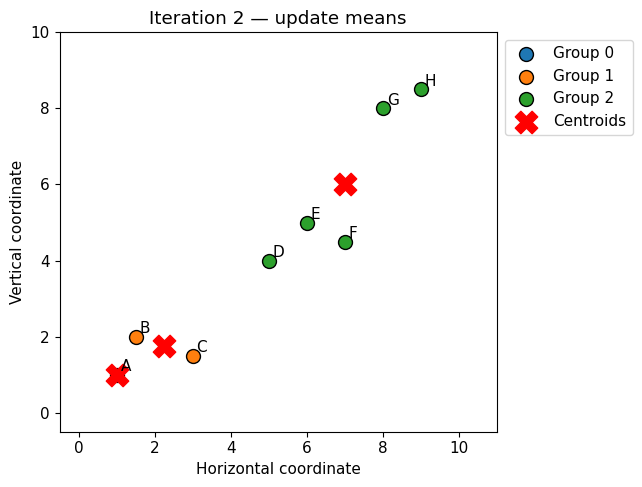

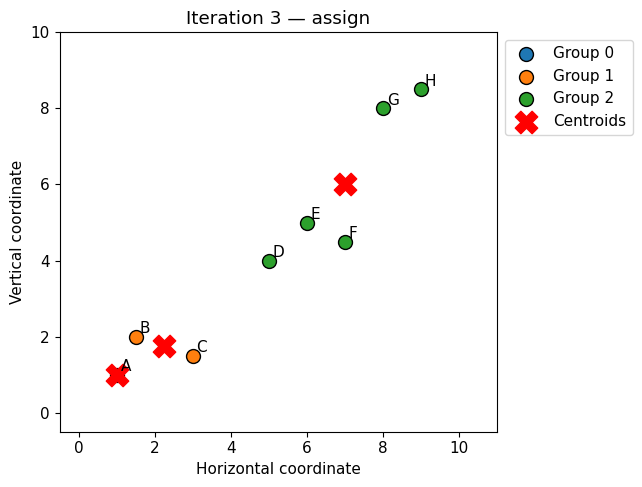

,Members,New x,New y
0,A,1.00,1.00
1,B C,2.25,1.75
2,D E F G H,7.00,6.00


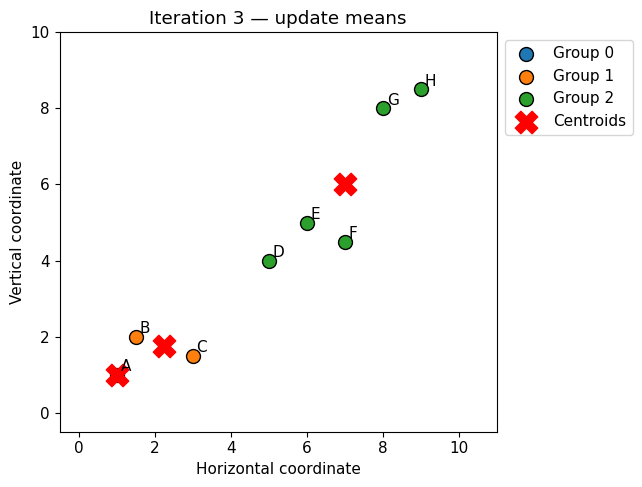

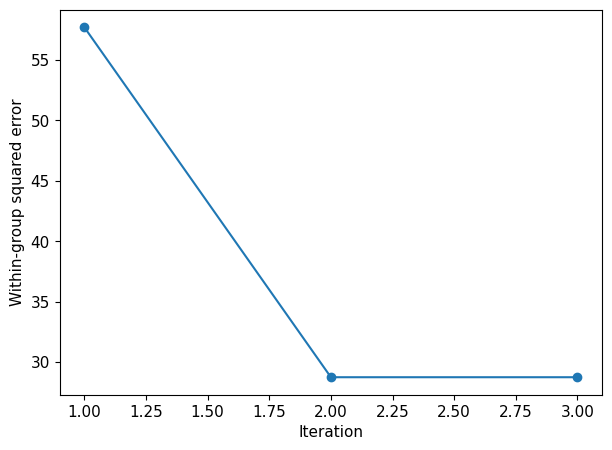

In [6]:
history = []
for iteration in range(1,21):
    distances = ((X[:,None,:]-centers[None,:,:])**2).sum(axis=2)
    assignments = distances.argmin(axis=1)
    plot_groups(X, assignments, f'Iteration {iteration} — assign', centers)
    updated = centers.copy()
    for group in range(3):
        members = X[assignments == group]
        if len(members):
            updated[group] = members.mean(axis=0)
    display(pd.DataFrame({'Members':[' '.join(names[assignments==g]) for g in range(3)],
                          'New x':updated[:,0], 'New y':updated[:,1]}))
    objective = ((X-updated[assignments])**2).sum()
    history.append(objective)
    plot_groups(X, assignments, f'Iteration {iteration} — update means', updated)
    converged = np.allclose(centers,updated)
    centers = updated
    if converged:
        break
assert converged
assert np.all(np.diff(history) <= 1e-9)
plt.plot(range(1,len(history)+1),history,'o-')
plt.xlabel('Iteration'); plt.ylabel('Within-group squared error'); plt.show()


## 4. Verify with scikit-learn
Use the same initial centers and one run. Cluster numbers are arbitrary. Adjusted Rand index (ARI) equals 1 when two partitions match, even if their group numbers differ.

In [7]:
from sklearn.cluster import KMeans
model = KMeans(n_clusters=3,init=initial,n_init=1,algorithm='lloyd',tol=1e-10).fit(X)
assert adjusted_rand_score(assignments,model.labels_) == 1
assert np.isclose(history[-1],model.inertia_)
print('Verified identical partition and objective.', model.inertia_)


Verified identical partition and objective. 28.75


## 5. Check another initialization
The first run converged to a local solution. Compare a more spread-out initialization and inspect both the groups and the objective.

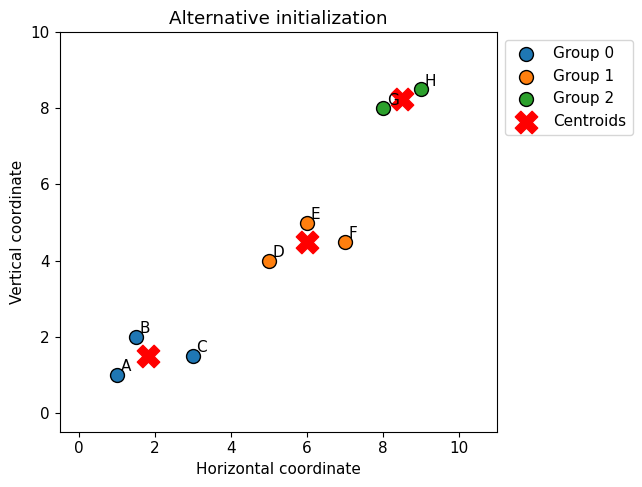

First objective: 28.75
Alternative objective: 5.791666666666666


In [8]:
alternative = KMeans(n_clusters=3,init=X[[0,3,7]],n_init=1,random_state=42).fit(X)
plot_groups(X,alternative.labels_,'Alternative initialization',alternative.cluster_centers_)
print('First objective:', model.inertia_)
print('Alternative objective:', alternative.inertia_)

## 6. Try and explain
1. Change the initial centers to `X[[0,3,7]]` and run from section 1. How many iterations are needed?
2. Explain why the center may be a location absent from the dataset.
3. Why do we specify the number of groups before fitting?

<details><summary>Instructor notes</summary>
The mean need not coincide with an observed point. Assignment and mean updates cannot increase the objective, but initialization can affect the local solution. These small coordinates share units. For mixed-scale customer variables, consider standardization. Use multiple initializations in practical K-Means.
</details>

Reference — [scikit-learn clustering guide](https://scikit-learn.org/stable/modules/clustering.html).